# Lab 05 · Simple Linear Regression
**CS-3105 Machine Learning Lab** · Lab Instructor: Engr. Muhammad Awais

**CLO 7** (C-3 Apply, PLO 4 Investigation): *Apply machine learning algorithms and assess their performance using appropriate evaluation metrics.*

**Goal:** build a complete price predictor for one car on real data: prepare the data, split it, train a simple linear regression with the least squares method, test it on unseen ads, and use it.

**Data:** `pakistan_used_cars_clean.csv`, the cleaned OLX Pakistan used-car ads from Lab 03 (Open Data Pakistan, 2021). Use the copy given with this lab so everyone has the same file.

Name: **SAQLAIN MUSHTAQ**  Roll No: **2024-SE-35**

### Setup (run first, do not edit)
Put `pakistan_used_cars_clean.csv` next to this notebook (Colab: folder icon → Upload).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
pd.set_option('display.width', 140)

## Task 1 · Load and explore the real data
- **(a)** Load `pakistan_used_cars_clean.csv` and print its shape.
- **(b)** Keep only **Corolla GLI**, **Cash** ads, `Year` 2005–2018 and `Price_lakh` between 5 and 40. Save it as `gli` and print the shape.
- **(c)** Summary statistics (`describe()`) of `Age` and `Price_lakh`.
- **(d)** The correlation between `Age` and `Price_lakh`.
- **(e)** A scatter plot of `Price_lakh` against `Age`, with a title and axis labels.

**Write (Markdown):** is a straight line a sensible model for this data? Use (d) and (e).

In [2]:
# T1: load and explore the real data
# (a) load the csv and print its shape (rows, columns)
df = pd.read_csv("pakistan_used_cars_clean.csv")
print("T1a: shape of full data =", df.shape)

# (b) keep only Corolla GLI, Cash ads, Year 2005-2018, Price_lakh 5-40
gli = df[
    (df["Model"] == "Corolla GLI")
    & (df["Transaction Type"] == "Cash")
    & (df["Year"].between(2005, 2018))        # between() is inclusive on both ends
    & (df["Price_lakh"].between(5, 40))
].copy()
print("T1b: shape of gli =", gli.shape)

# (c) summary statistics of Age and Price_lakh
print("T1c: summary statistics")
print(gli[["Age", "Price_lakh"]].describe())

# (d) correlation between Age and Price_lakh
corr = gli["Age"].corr(gli["Price_lakh"])
print("T1d: correlation(Age, Price_lakh) =", round(corr, 4))

# (e) scatter plot
plt.figure(figsize=(7, 5))
plt.scatter(gli["Age"], gli["Price_lakh"], alpha=0.5, s=20)
plt.title("Corolla GLI: Price vs Age")
plt.xlabel("Age (years) = 2020 - Year")
plt.ylabel("Price (lakh PKR)")
plt.grid(alpha=0.3)
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'pakistan_used_cars_clean.csv'

**Answer (Task 1):** Yes, a straight line is a sensible model for this data. The correlation between `Age` and `Price_lakh` is **-0.8957**, which is a strong negative linear relationship: as the car gets older, the price goes down. The scatter plot agrees: the points form a downward band from about 22-25 lakh at age 2 to about 8-10 lakh at age 15, and they follow a roughly straight trend. There is some spread around the band (cars of the same age have different prices because of mileage, condition and city), and a few odd ads at age 2, but the overall pattern is a line. The only small doubt is that the band curves slightly (it falls a bit faster for new cars), which is checked again in Task 6.

## Task 2 · Features, target and the train/test split
- **(a)** `X` = the `Age` column as a **2-D** table, `y` = `Price_lakh`. Print both shapes.
- **(b)** Split 80 % train / 20 % test with `train_test_split(..., test_size=0.2, random_state=42)`. Print the four shapes.

In [ ]:
# T2: features, target, split
# (a) X must be 2-D, so we use double brackets [["Age"]] (a DataFrame), y is 1-D (a Series)
X = gli[["Age"]]
y = gli["Price_lakh"]
print("T2a: X shape =", X.shape, "| y shape =", y.shape)

# (b) 80/20 split, random_state=42 so everybody gets the same split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("T2b: X_train", X_train.shape, "| X_test", X_test.shape,
      "| y_train", y_train.shape, "| y_test", y_test.shape)


T2a: X shape = (796, 1) | y shape = (796,)
T2b: X_train (636, 1) | X_test (160, 1) | y_train (636,) | y_test (160,)


## Task 3 · Least squares with NumPy (training data only)
Use only `X_train` and `y_train`, and NumPy (no scikit-learn):
- **(a)** The means x̄ and ȳ.
- **(b)** The slope b₁ = Σ(x − x̄)(y − ȳ) / Σ(x − x̄)² and the intercept b₀ = ȳ − b₁x̄.
- **(c)** **Write (Markdown):** what b₁ and b₀ mean for a Corolla GLI, with units.

In [ ]:
# T3: least squares with NumPy, TRAINING data only
x = X_train["Age"].to_numpy()      # 1-D arrays are easiest for the formulas
yv = y_train.to_numpy()

# (a) means
x_bar = x.mean()
y_bar = yv.mean()
print("T3a: x_bar (mean Age) =", round(x_bar, 4), "| y_bar (mean Price_lakh) =", round(y_bar, 4))

# (b) slope and intercept
b1 = np.sum((x - x_bar) * (yv - y_bar)) / np.sum((x - x_bar) ** 2)
b0 = y_bar - b1 * x_bar
print("T3b: slope b1 =", round(b1, 4), "| intercept b0 =", round(b0, 4))


T3a: x_bar (mean Age) = 6.3821 | y_bar (mean Price_lakh) = 16.6533
T3b: slope b1 = -1.146 | intercept b0 = 23.9669


**Answer (Task 3c):**
- **b₁ = -1.146 lakh PKR per year.** For every extra year of age, the predicted price of a Corolla GLI drops by about **1.15 lakh rupees** (about Rs 114,600), on average.
- **b₀ = 23.967 lakh PKR.** This is the predicted price when Age = 0, i.e. a brand-new (current-year) Corolla GLI: about **24 lakh rupees**. It is an extrapolation, because the training data starts at age 2 and no age-0 car exists in the data, so b₀ is mainly the starting point of the line and should not be taken as an exact new-car price.

## Task 4 · Train the model with scikit-learn
- **(a)** Create a `LinearRegression()` model, fit it on the **training** data and print the slope (`coef_`) and intercept (`intercept_`).
- **(b)** Show with `np.isclose` that they equal your Task 3 values.

In [ ]:
# T4: train with scikit-learn
# (a) fit on TRAINING data only
model = LinearRegression()
model.fit(X_train, y_train)
print("T4a: slope (coef_) =", round(model.coef_[0], 4), "| intercept_ =", round(model.intercept_, 4))

# (b) compare with our manual NumPy values from Task 3
print("T4b: slope equal?     ", np.isclose(model.coef_[0], b1))
print("T4b: intercept equal? ", np.isclose(model.intercept_, b0))


T4a: slope (coef_) = -1.146 | intercept_ = 23.9669
T4b: slope equal?      True
T4b: intercept equal?  True


## Task 5 · Evaluate on the test set
- **(a)** Predict the test prices. Compute MAE, MSE, RMSE and R² **with the formulas** in NumPy.
- **(b)** Check MAE, MSE and R² with `sklearn.metrics`.
- **(c)** Train R² and test R². Is the model overfitting?
- **(d)** Baseline: predict the **training mean** for every test ad. Its MAE and R².

**Write (Markdown):** explain MAE and R² of your model in plain words, and how much better it is than the baseline.

In [ ]:
# T5: evaluate on the TEST set
y_true = y_test.to_numpy()
y_pred = model.predict(X_test)
n = len(y_true)

# (a) metrics with the formulas in NumPy
mae  = np.sum(np.abs(y_true - y_pred)) / n
mse  = np.sum((y_true - y_pred) ** 2) / n
rmse = np.sqrt(mse)
ss_res = np.sum((y_true - y_pred) ** 2)
ss_tot = np.sum((y_true - y_true.mean()) ** 2)
r2 = 1 - ss_res / ss_tot
print("T5a: MAE  =", round(mae, 4), "lakh")
print("T5a: MSE  =", round(mse, 4), "lakh^2")
print("T5a: RMSE =", round(rmse, 4), "lakh")
print("T5a: R2   =", round(r2, 4))

# (b) check with sklearn.metrics
print("T5b: MAE  sklearn =", round(mean_absolute_error(y_true, y_pred), 4), "| same?", np.isclose(mae, mean_absolute_error(y_true, y_pred)))
print("T5b: MSE  sklearn =", round(mean_squared_error(y_true, y_pred), 4), "| same?", np.isclose(mse, mean_squared_error(y_true, y_pred)))
print("T5b: R2   sklearn =", round(r2_score(y_true, y_pred), 4), "| same?", np.isclose(r2, r2_score(y_true, y_pred)))

# (c) train R2 vs test R2
r2_train = r2_score(y_train, model.predict(X_train))
r2_test = r2_score(y_test, y_pred)
print("T5c: train R2 =", round(r2_train, 4), "| test R2 =", round(r2_test, 4),
      "| gap =", round(r2_train - r2_test, 4))

# (d) baseline: always predict the TRAINING mean
baseline_pred = np.full(n, y_train.mean())
base_mae = mean_absolute_error(y_true, baseline_pred)
base_r2 = r2_score(y_true, baseline_pred)
print("T5d: baseline (train mean =", round(y_train.mean(), 4), ") MAE =", round(base_mae, 4), "| R2 =", round(base_r2, 4))
print("T5d: MAE improvement over baseline =", round((1 - mae / base_mae) * 100, 1), "%")


T5a: MAE  = 1.1849 lakh
T5a: MSE  = 2.7043 lakh^2
T5a: RMSE = 1.6445 lakh
T5a: R2   = 0.8452
T5b: MAE  sklearn = 1.1849 | same? True
T5b: MSE  sklearn = 2.7043 | same? True
T5b: R2   sklearn = 0.8452 | same? True
T5c: train R2 = 0.7897 | test R2 = 0.8452 | gap = -0.0555
T5d: baseline (train mean = 16.6533 ) MAE = 3.5044 | R2 = -0.0064
T5d: MAE improvement over baseline = 66.2 %


**Answer (Task 5):**
- **MAE = 1.18 lakh:** on average the model's predicted price is wrong by about 1.18 lakh rupees (about Rs 118,000) on unseen cars.
- **RMSE = 1.64 lakh** is larger than MAE because squaring punishes big mistakes (a few ads, especially the 10.8-lakh 2018 ad, are far from the line).
- **R² = 0.845:** the model explains about **84.5 %** of the variation in test prices using age alone. The remaining ~15.5 % is due to other things (mileage, condition, city, ...).
- **Overfitting? No.** Train R² = 0.790 and test R² = 0.845. The test score is not lower than the train score, so the model is not overfitting. (Test being slightly higher is just a chance effect of which ads landed in the 160-ad test set. With one feature and two parameters, a line cannot really overfit 636 points.)
- **Baseline (always predict the training mean, 16.65 lakh):** MAE = 3.50 lakh and R² = -0.006 (about zero, as expected for a model that ignores age). Our model's MAE of 1.18 is about **66 % smaller** (about 3 times better), and R² goes from about 0 to 0.845. So age carries a lot of useful information.

## Task 6 · Visualise the line and the errors
- **(a)** One plot: training ads (grey), test ads, and the fitted line. Title, labels, legend.
- **(b)** A residual plot for the test set: residual (y − ŷ) against predicted price, with a line at 0.
- **(c)** The five test ads with the largest absolute error: `Year`, `KMs Driven`, `Registered City`, actual and predicted price.

**Write (Markdown):** does the residual plot show a curve or a funnel? Are the largest errors mistakes of the model or of the data?

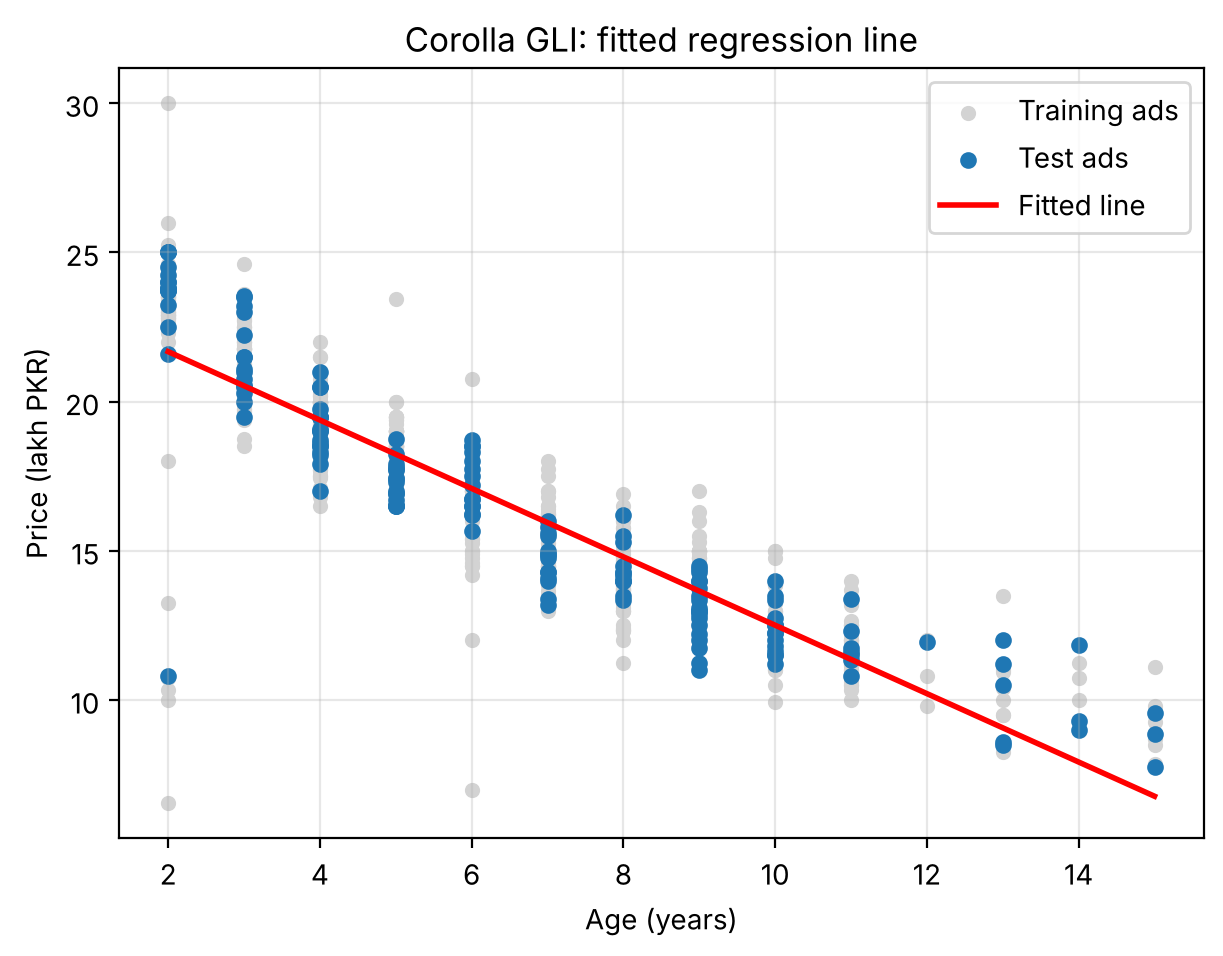

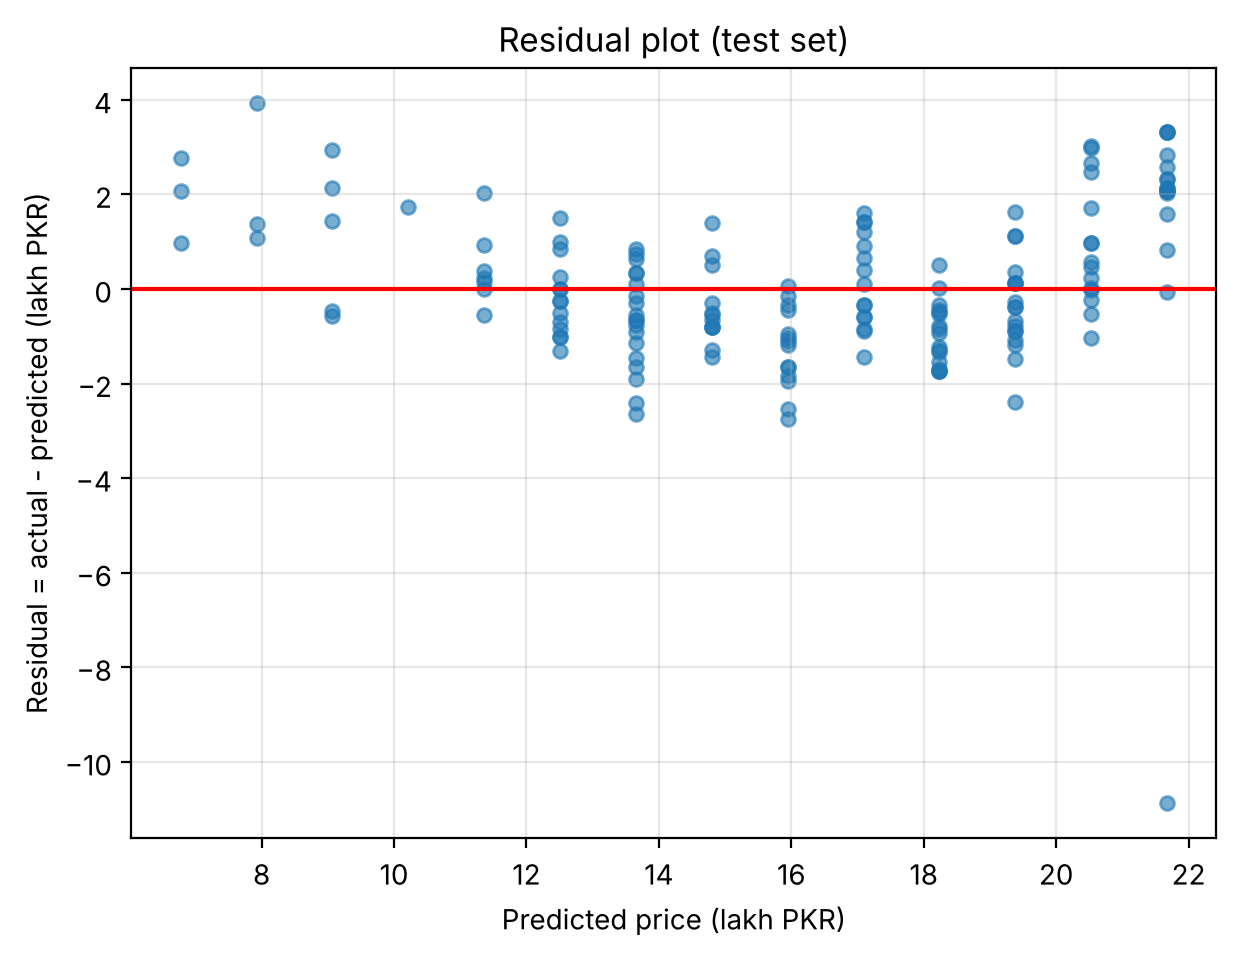

T6c: five largest absolute errors
       Year  KMs Driven Registered City  Actual  Predicted  Abs_error
18857  2018         NaN         Unknown   10.80      21.67      10.87
20280  2006    220000.0       Islamabad   11.85       7.92       3.93
17363  2018         NaN         Unknown   25.00      21.67       3.33
18980  2018         NaN         Unknown   25.00      21.67       3.33
16557  2018       300.0         Unknown   25.00      21.67       3.33


In [ ]:
# T6: visualise the line and the errors
# (a) training ads (grey), test ads, fitted line
plt.figure(figsize=(7, 5))
plt.scatter(X_train["Age"], y_train, color="lightgrey", s=20, label="Training ads")
plt.scatter(X_test["Age"], y_test, color="tab:blue", s=25, label="Test ads")
line_x = pd.DataFrame({"Age": np.linspace(gli["Age"].min(), gli["Age"].max(), 100)})
plt.plot(line_x["Age"], model.predict(line_x), color="red", linewidth=2, label="Fitted line")
plt.title("Corolla GLI: fitted regression line")
plt.xlabel("Age (years)")
plt.ylabel("Price (lakh PKR)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# (b) residual plot (test set): residual = actual - predicted
residuals = y_true - y_pred
plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.6, s=25)
plt.axhline(0, color="red", linewidth=1.5)
plt.title("Residual plot (test set)")
plt.xlabel("Predicted price (lakh PKR)")
plt.ylabel("Residual = actual - predicted (lakh PKR)")
plt.grid(alpha=0.3)
plt.show()

# (c) five test ads with the largest absolute error
check = gli.loc[X_test.index, ["Year", "KMs Driven", "Registered City"]].copy()
check["Actual"] = y_true
check["Predicted"] = y_pred.round(2)
check["Abs_error"] = np.abs(residuals).round(2)
print("T6c: five largest absolute errors")
print(check.sort_values("Abs_error", ascending=False).head(5))


**Answer (Task 6):**
- **Residual plot:** there is **a mild curve (U-shape), not a clear funnel.** The line over-predicts in the middle ages (about 4-9 years) and under-predicts for the youngest cars (age 2-3) and the oldest cars (age 11-15). Real depreciation is slightly curved (new cars lose value faster, old cars flatten out), while a line is straight. Also the spread is larger for age-2 cars than for the others, which is a small funnel effect at the new-car end. This is a mild problem, not a serious one, and R² = 0.845 is still good.
- **Largest errors - mixed:**
  - **Data mistake (most likely):** the biggest error is a 2018 ad priced at 10.8 lakh while similar 2018 cars sell for about 22-25 lakh (error about 10.9 lakh). This looks like a price entry error or a wrong year, not a model failure.
  - **Model limit:** the 2006 car (age 14) is priced at 11.85 lakh but the line predicts 7.92 lakh. Here the line under-predicts old cars because of the curve described above.
  - **Model limit + missing information:** three 2018 cars at 25 lakh are about 3.3 lakh above the line (21.67 lakh). These are probably higher-priced / better-condition cars, and the ads have missing `KMs Driven` or unknown city, which age alone cannot explain.
  - So some errors come from bad data and some from the model using only age.

## Task 7 · Use the model
- **(a)** Predict the price of a 2018, a 2015 and a 2010 Corolla GLI (age = 2020 − year), using a DataFrame with an `Age` column.
- **(b)** Predict the price of a 1995 Corolla GLI (age 25).

**Write (Markdown):** is the answer in (b) believable? Why not?

In [ ]:
# T7: use the model
# (a) 2018, 2015, 2010 -> age = 2020 - year
years = [2018, 2015, 2010]
new_cars = pd.DataFrame({"Age": [2020 - yr for yr in years]})   # column name must be "Age" like in training
for yr, age, p in zip(years, new_cars["Age"], model.predict(new_cars)):
    print(f"T7a: {yr} Corolla GLI (age {age}) -> predicted price = {p:.2f} lakh")

# (b) 1995 Corolla GLI (age 25) - far outside the training range
old_car = pd.DataFrame({"Age": [25]})
print("T7b: 1995 Corolla GLI (age 25) -> predicted price =", round(model.predict(old_car)[0], 2), "lakh")
print("T7b: training Age range was", gli["Age"].min(), "to", gli["Age"].max())


T7a: 2018 Corolla GLI (age 2) -> predicted price = 21.67 lakh
T7a: 2015 Corolla GLI (age 5) -> predicted price = 18.24 lakh
T7a: 2010 Corolla GLI (age 10) -> predicted price = 12.51 lakh
T7b: 1995 Corolla GLI (age 25) -> predicted price = -4.68 lakh
T7b: training Age range was 2 to 15


**Answer (Task 7b):** No, the answer is **not believable.** The model predicts **-4.68 lakh**, a *negative* price, which is impossible (a car cannot have a negative price; even an old classic 1995 Corolla is worth something). The reason is **extrapolation:** the model was trained on ages 2 to 15 only, and age 25 is far outside that range. A straight line keeps going down forever, so for large ages it crosses zero (at about age 21) and becomes negative. A linear model is only trustworthy inside the range of data it has seen. Also, very old cars are priced by condition and collector value, not by simple depreciation.

## Task 8 · Reflection (Markdown cell)
Write 3–5 sentences: the steps you followed to build the model, why the model is judged on the test set and not the training set, which number you would tell a car buyer and why, and one limitation of using age alone.

**Reflection:** I loaded the OLX data, filtered it to Cash-priced Corolla GLI ads from 2005-2018 with sensible prices, checked the correlation and scatter plot, split the data 80/20 with `random_state=42`, computed the least-squares slope and intercept by hand in NumPy, confirmed them with `LinearRegression`, and then evaluated the model with MAE, RMSE, R² and a mean-only baseline. The model is judged on the **test set** because the training ads were used to choose the line, so training scores are optimistic; only unseen ads show how the model will behave on a real new customer. I would tell a car buyer the **MAE (about 1.2 lakh)**, because it is in rupees and easy to understand ("the estimate is usually within about 1.2 lakh of the real price"), while R² is not very meaningful for a buyer. A limitation of using age alone is that it ignores mileage, condition, city and car version, so two cars of the same age but very different mileage get the same predicted price, and the model cannot predict outside the age range 2-15.